In [ ]:
## Written by Erol Balkovic
## EPFL 5/5/2026
## erol.balkovic@epfl.ch

In [1]:
from simsopt.configs.zoo import get_data
from simsopt.mhd import Vmec

import numpy as np
import matplotlib.pyplot as plt

from spectre import SPECTRE, SPECTREout
from spectre.file_io import write_input_parameters_to_toml
from spectre.converters import simsvmec2spectre
from spectre.converters import (fix2free,
    params_to_simsopt_boundary,
    plot_freeboundary_modes,
)

%load_ext autoreload
%autoreload 2
#%matplotlib ipympl

/home/smiet/code/pyoculus/pyoculus/fields/two_waves.py:111: SyntaxWarning: invalid escape sequence '\ '
  """! Convert coordinates for Poincare plots
/home/smiet/code/pyoculus/pyoculus/maps/tokamap.py:111: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/maps/standard_map.py:90: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/manifold.py:264: SyntaxWarning: invalid escape sequence '\S'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:96: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:134: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line, internal function
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:204: SyntaxWarning: invalid escape sequence '\z'
  """! Construct a QFM surface based on Stuart's method, for a given orbit periodicit

In [2]:
## Load W7-X coils from simsopt zoo
_, _, _, _, bs_obj = get_data("w7x")
print(f"Number of coils (full torus): {len(bs_obj.coils)}")

Number of coils (full torus): 70


In [12]:
## Build fixed-boundary SPECTRE input from W7-X VMEC

vmec = Vmec("input.W7-X_standard_configuration")
params = simsvmec2spectre(vmec, mpol=18, ntor=18, interface_guess='map2disc', tfluxes=[0.2, 1.])

print(f"nvol={params.physics.nvol}, mpol={params.physics.mpol}, ntor={params.physics.ntor}")
print(f"lfreebound={params.physics.lfreebound}, lconstraint={params.physics.lconstraint}")

 - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
  VMEC OUTPUT FILES ALREADY EXIST: OVERWRITING THEM ...
  SEQ =    1 TIME SLICE  0.0000E+00
  PROCESSING INPUT.W7-X_standard_configuration
  THIS IS PARVMEC (PARALLEL VMEC), VERSION 9.0
  Lambda: Full Radial Mesh. L-Force: hybrid full/half.

  COMPUTER:    OS:    RELEASE:   DATE = Jul 27,2026  TIME = 20:40:46
nvol=2, mpol=18, ntor=18
lfreebound=0, lconstraint=3


  qfm residual start = 3.9709e-03
  qfm residual end   = 1.7469e-03  (8 LBFGS iters)


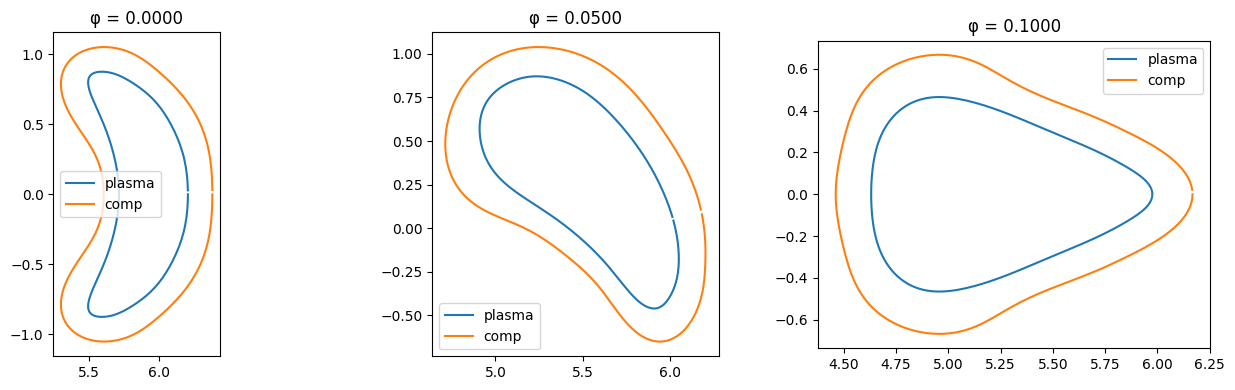

In [13]:
## Build plasma boundary from InputParameters, then extend to computational boundary
from simsopt.geo import QfmResidual, QfmSurface, ToroidalFlux
from simsopt.field import BiotSavart

plasma_boundary = params_to_simsopt_boundary(params, which="plasma")
comp_boundary = plasma_boundary.copy(mpol=7,ntor=7)
comp_boundary.extend_via_normal(-0.17)   # negative → outward

qfm = QfmResidual(comp_boundary, bs_obj)
print(f"  qfm residual start = {qfm.J():.4e}")
tf = ToroidalFlux(comp_boundary, BiotSavart(bs_obj.coils))
qfm_surface = QfmSurface(bs_obj, comp_boundary, tf, tf.J())
qfm_surface.minimize_qfm_penalty_constraints_LBFGS(tol=1e-12, maxiter=8)
print(f"  qfm residual end   = {qfm.J():.4e}  ({8} LBFGS iters)")





# Plot original vs extended cross-sections
nfp = plasma_boundary.nfp
phis = [0.0, 1 / (4 * nfp), 1 / (2 * nfp)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for phi, ax in zip(phis, axes):
    for surf, label in [(plasma_boundary, "plasma"), (comp_boundary, "comp")]:
        cs = surf.cross_section(phi=phi, thetas=200)
        R = np.sqrt(cs[:, 0] ** 2 + cs[:, 1] ** 2)
        ax.plot(R, cs[:, 2], label=label)
    ax.set_aspect("equal")
    ax.set_title(f"φ = {phi:.4f}")
    ax.legend()
fig.tight_layout()

/tmp/ipykernel_16337/2156588454.py:3: UserWarning: curpol not given; auto-computing it as sign(B_φ_coils)·μ₀·Σ|I_coil| over all coils in bs.coils. This assumes every coil is a modular coil that links the plasma exactly once in the same direction. For coil sets with non-modular coils (toroidal-field, PF, windowpane) or coils that link the plasma more than once, this mis-counts the poloidal linking current — pass curpol explicitly in that case.
  result = fix2free(


lfreebound : 1
nvol       : 2
curpol     : -101.8 T·m
phiedge    : -2.191 Wb
tflux[nvol-1:nvol+1] : [1.         2.05818635]
B·n truncation at (mpol=18, ntor=18): 1.79% of spectral RMS lies outside the kept band


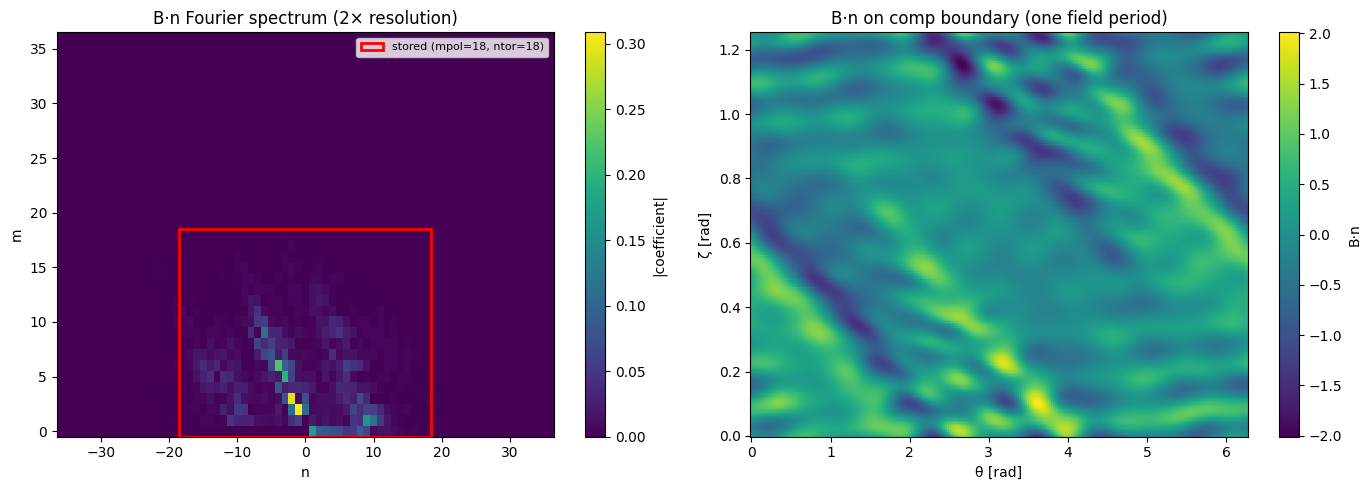

In [14]:
## Convert to free boundary and write TOML

result = fix2free(
    params, bs_obj, comp_boundary,
    filename='w7x_freeb.toml', vacuum=True
)

write_input_parameters_to_toml(result, 'w7x_vacuum.toml')
nvol = result.physics.nvol
print(f"lfreebound : {result.physics.lfreebound}")
print(f"nvol       : {nvol}")
print(f"curpol     : {result.physics.curpol:.4g} T·m")
print(f"phiedge    : {result.physics.phiedge:.4g} Wb")
print(f"tflux[nvol-1:nvol+1] : {result.physics.tflux[nvol - 1 : nvol + 1]}")


fig = plot_freeboundary_modes(bs_obj, result, log_scale=False)  # linear scale: see which modes dominate
plt.show()

In [ ]:
## Run SPECTRE, trace field lines, and plot Poincaré section. This is not a converged equilibrium, but we can look at the unconverged state. 

spectre = SPECTRE.from_input_params(result, name="w7x_freeb")
spectre.run()

# force SPECTRE to evaluate the field by calling these functions: 
from spectre import get_xinit_specwrap,get_fmn_force_mask
xin = get_xinit_specwrap(spectre)
mask = get_fmn_force_mask(spectre)

out = spectre.create_spectreout()

# Initial points: evenly spaced in s ∈ (-1, 1), θ = 0, one array per volume
num_trajectories = 8
num_transits = 5
mvol = out.input.physics.Mvol

init_pts = [
    np.array([[x, 0.0] for x in np.linspace(-.95, .95, 2)]),
    np.array([[x, 0.0] for x in np.linspace(-.95, .95, 15)]), 
    np.array([[x, 0.0] for x in np.linspace(-.95, .95, 15)]), 
]

out.trace_fieldlines(init_pts, num_phi_planes=32, num_transits=num_transits)

fig, ax = plt.subplots(figsize=(8, 7))
out.tracer.plot(ax=ax)
out.plot_infaces(ax=ax)
ax.set_aspect("equal")
ax.set_title("W7-X Poincaré section (ζ = 0)")
plt.tight_layout()
plt.show()